# Árvore, floresta ou boosting? Experimento com o NSL-KDD

Neste notebook a gente compara Árvore de Decisão, Random Forest e XGBoost num detector de intrusão:
para cada conexão de rede, o modelo diz se ela é **normal** ou **ataque**.

O que vamos fazer:
1. Carregar o NSL-KDD usando a divisão oficial (KDDTrain+ para treino e KDDTest+ para teste).
2. Começar por uma árvore pequena, para entender como ela decide, e depois ver o overfitting.
3. Testar os hiperparâmetros principais da Random Forest e do XGBoost.
4. Ajustar os três modelos com o mesmo esforço (15 combinações cada, validação cruzada só no treino).
5. Avaliar no teste uma única vez: precisão, recall, F1, matriz de confusão, curva ROC, tempos e recall por categoria de ataque.
6. Olhar a interpretabilidade de cada modelo.

Importante: o conjunto de teste só aparece a partir da seção 5. Nada de ajuste usando o teste.

## 0. Configuração
No Colab as bibliotecas já vêm instaladas. Se for rodar no computador, use `pip install -r requirements.txt`.

In [1]:
import os
import time
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost
from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from scipy.stats import randint, uniform, loguniform

# semente fixa para todo mundo conseguir os mesmos números
SEED = 42
np.random.seed(SEED)

os.makedirs("figuras", exist_ok=True)
os.makedirs("resultados", exist_ok=True)

# versões usadas (vão para o README e para a página)
print("Python      ", platform.python_version())
print("scikit-learn", sklearn.__version__)
print("xgboost     ", xgboost.__version__)
print("pandas      ", pd.__version__)
print("numpy       ", np.__version__)

Python       3.13.16
scikit-learn 1.6.1
xgboost      3.4.1
pandas       2.2.3
numpy        2.1.3


## 1. Os dados
O NSL-KDD é uma versão corrigida do KDD Cup 99, sem os registros repetidos. Cada linha é uma conexão de rede com
41 atributos (duração, protocolo, serviço, bytes enviados, taxas de erro etc.) e um rótulo, que é `normal` ou o nome do ataque.

Fonte: Canadian Institute for Cybersecurity (UNB), https://www.unb.ca/cic/datasets/nsl.html

Os arquivos são baixados direto da internet, por isso não colocamos os dados no repositório.

In [2]:
URL_BASE = "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/"

colunas = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted", "num_root",
    "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds",
    "is_host_login", "is_guest_login", "count", "srv_count", "serror_rate",
    "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
    "diff_srv_rate", "srv_diff_host_rate", "dst_host_count",
    "dst_host_srv_count", "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate", "dst_host_srv_serror_rate", "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate", "label", "difficulty",
]

treino_df = pd.read_csv(URL_BASE + "KDDTrain+.txt", header=None, names=colunas)
teste_df = pd.read_csv(URL_BASE + "KDDTest+.txt", header=None, names=colunas)
print("treino:", treino_df.shape)
print("teste: ", teste_df.shape)
treino_df.head()

treino: (125973, 43)
teste:  (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


### O que vamos prever
Transformamos o rótulo em 0 (normal) e 1 (ataque).

Também agrupamos os ataques nas quatro categorias de sempre do NSL-KDD, para ver depois onde os modelos erram mais:
- **DoS**: derrubar um serviço com excesso de requisições
- **Probe**: varredura em busca de portas e máquinas
- **R2L**: acesso remoto sem ter conta na máquina (ex.: adivinhar senha)
- **U2R**: um usuário comum tentando virar root

Um detalhe que pesa muito: o KDDTest+ tem tipos de ataque que **não aparecem no treino**.

In [3]:
categorias = {
    "DoS": ["back", "land", "neptune", "pod", "smurf", "teardrop",
            "apache2", "mailbomb", "processtable", "udpstorm"],
    "Probe": ["ipsweep", "nmap", "portsweep", "satan", "mscan", "saint"],
    "R2L": ["ftp_write", "guess_passwd", "imap", "multihop", "phf", "spy",
            "warezclient", "warezmaster", "sendmail", "named", "snmpgetattack",
            "snmpguess", "xlock", "xsnoop", "worm"],
    "U2R": ["buffer_overflow", "loadmodule", "perl", "rootkit",
            "httptunnel", "ps", "sqlattack", "xterm"],
}
ataque_para_categoria = {a: cat for cat, lista in categorias.items() for a in lista}
ataque_para_categoria["normal"] = "normal"

for df in (treino_df, teste_df):
    df["ataque"] = (df["label"] != "normal").astype(int)
    df["categoria"] = df["label"].map(ataque_para_categoria)

# conferindo se nenhum rótulo ficou sem categoria
print("sem categoria:", treino_df["categoria"].isna().sum() + teste_df["categoria"].isna().sum())

print("\nProporção de ataques no treino: %.1f%%" % (100 * treino_df["ataque"].mean()))
print("Proporção de ataques no teste:  %.1f%%" % (100 * teste_df["ataque"].mean()))

tipos_novos = sorted(set(teste_df["label"]) - set(treino_df["label"]))
n_novos = teste_df["label"].isin(tipos_novos).sum()
print(f"\nTipos de ataque que só existem no teste: {len(tipos_novos)}")
print(tipos_novos)
print(f"Isso dá {n_novos} registros ({100 * n_novos / len(teste_df):.1f}% do teste)")

pd.crosstab(teste_df["categoria"], teste_df["label"].isin(tipos_novos).map({False: "conhecido", True: "novo"}))

sem categoria: 0

Proporção de ataques no treino: 46.5%
Proporção de ataques no teste:  56.9%

Tipos de ataque que só existem no teste: 17
['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']
Isso dá 3750 registros (16.6% do teste)


label,conhecido,novo
categoria,,
DoS,5741,1717
Probe,1106,1315
R2L,2199,555
U2R,37,163
normal,9711,0


### Preparando os atributos
Árvores não precisam de normalização, mas precisam de números. Os três atributos de texto (`protocol_type`, `service` e `flag`)
viram colunas de 0 e 1 (one-hot). Depois deixamos o teste com as mesmas colunas do treino: se aparecer um serviço que
só existe no teste, ele fica zerado, porque o modelo nunca viu esse serviço.

In [4]:
categoricas = ["protocol_type", "service", "flag"]
descartar = ["label", "difficulty", "ataque", "categoria"]

X_train = pd.get_dummies(treino_df.drop(columns=descartar), columns=categoricas, dtype=int)
X_test = pd.get_dummies(teste_df.drop(columns=descartar), columns=categoricas, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
y_train = treino_df["ataque"].values
y_test = teste_df["ataque"].values
print("número de atributos depois do one-hot:", X_train.shape[1])

# Separamos 20% do TREINO como validação, só para os gráficos das seções 2 e 3.
# O teste continua guardado.
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEED)

número de atributos depois do one-hot: 122


## 2. Árvore de Decisão
### Uma árvore pequena primeiro
Vamos treinar uma árvore com profundidade 3 e só 7 atributos, para dar para ler as regras.

|--- src_bytes <= 28.50
|   |--- dst_host_srv_count <= 208.50
|   |   |--- dst_bytes <= 3.50
|   |   |   |--- class: 1
|   |   |--- dst_bytes >  3.50
|   |   |   |--- class: 0
|   |--- dst_host_srv_count >  208.50
|   |   |--- src_bytes <= 0.50
|   |   |   |--- class: 0
|   |   |--- src_bytes >  0.50
|   |   |   |--- class: 1
|--- src_bytes >  28.50
|   |--- count <= 324.50
|   |   |--- src_bytes <= 41133.50
|   |   |   |--- class: 0
|   |   |--- src_bytes >  41133.50
|   |   |   |--- class: 1
|   |--- count >  324.50
|   |   |--- dst_bytes <= 2.00
|   |   |   |--- class: 1
|   |   |--- dst_bytes >  2.00
|   |   |   |--- class: 0

F1 na validação: 0.957


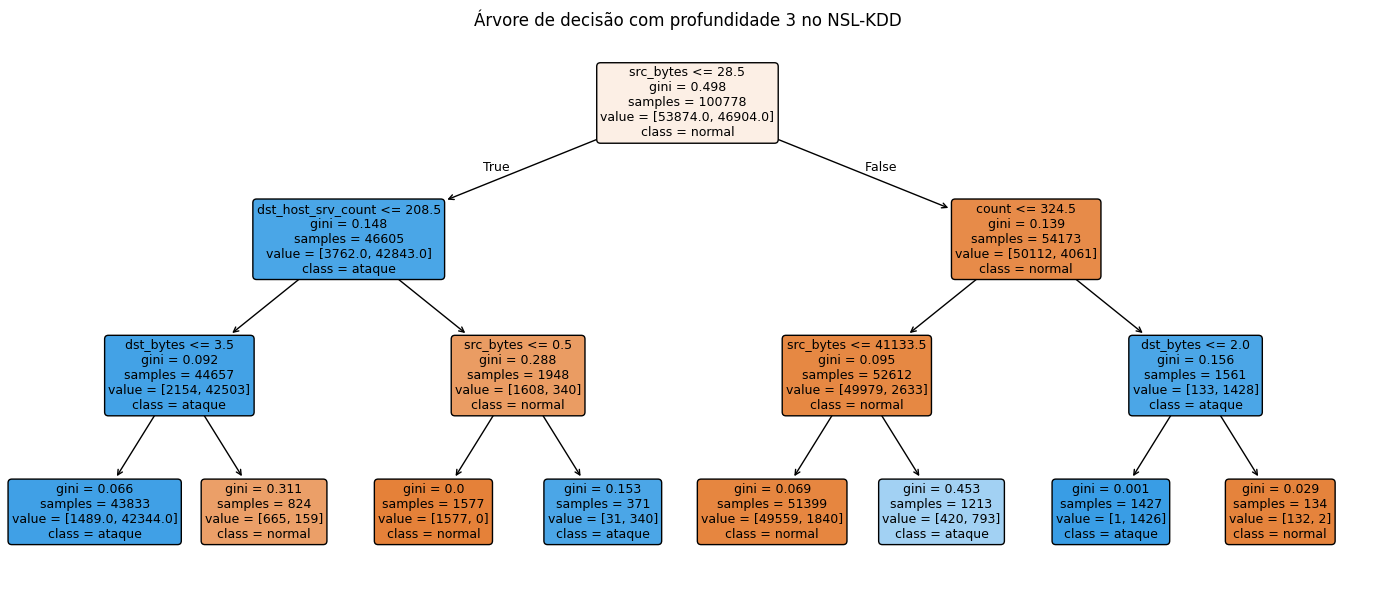

In [5]:
poucos = ["src_bytes", "dst_bytes", "count", "same_srv_rate",
          "dst_host_srv_count", "logged_in", "serror_rate"]

arvore_rasa = DecisionTreeClassifier(max_depth=3, random_state=SEED)
arvore_rasa.fit(X_tr[poucos], y_tr)

# as regras em texto
print(export_text(arvore_rasa, feature_names=poucos))
print("F1 na validação: %.3f" % f1_score(y_val, arvore_rasa.predict(X_val[poucos])))

fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(arvore_rasa, feature_names=poucos, class_names=["normal", "ataque"],
          filled=True, rounded=True, fontsize=9, ax=ax)
ax.set_title("Árvore de decisão com profundidade 3 no NSL-KDD")
plt.tight_layout()
plt.savefig("figuras/arvore_rasa.png", dpi=150)
plt.show()

### Overfitting: o que acontece quando a árvore fica mais funda
Treinamos árvores cada vez mais profundas e comparamos o F1 no treino e na validação.

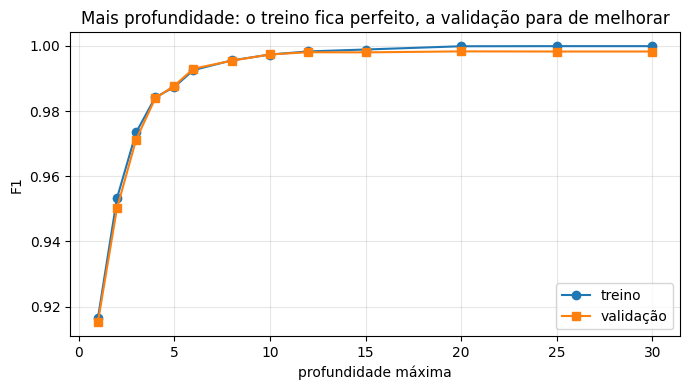

In [6]:
profundidades = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, 30]
f1_treino, f1_validacao = [], []

for d in profundidades:
    arvore = DecisionTreeClassifier(max_depth=d, random_state=SEED).fit(X_tr, y_tr)
    f1_treino.append(f1_score(y_tr, arvore.predict(X_tr)))
    f1_validacao.append(f1_score(y_val, arvore.predict(X_val)))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(profundidades, f1_treino, "o-", label="treino")
ax.plot(profundidades, f1_validacao, "s-", label="validação")
ax.set_xlabel("profundidade máxima")
ax.set_ylabel("F1")
ax.set_title("Mais profundidade: o treino fica perfeito, a validação para de melhorar")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figuras/overfitting_profundidade.png", dpi=150)
plt.show()

### Variância: a árvore muda bastante com pequenas mudanças nos dados
Treinamos 10 árvores, cada uma numa amostra bootstrap diferente do treino (sorteio com reposição),
e vemos o quanto o F1 na validação varia. Depois repetimos com florestas de 50 árvores.

In [7]:
def f1_em_bootstraps(criar_modelo, n=10):
    rng = np.random.RandomState(SEED)
    notas = []
    for i in range(n):
        idx = rng.randint(0, len(X_tr), len(X_tr))
        modelo = criar_modelo(SEED + i).fit(X_tr.iloc[idx], y_tr[idx])
        notas.append(f1_score(y_val, modelo.predict(X_val)))
    return np.array(notas)

notas_arvore = f1_em_bootstraps(lambda s: DecisionTreeClassifier(random_state=s))
notas_floresta = f1_em_bootstraps(lambda s: RandomForestClassifier(n_estimators=50, n_jobs=-1, random_state=s))

print("Árvore  : F1 médio %.4f | desvio padrão %.4f" % (notas_arvore.mean(), notas_arvore.std()))
print("Floresta: F1 médio %.4f | desvio padrão %.4f" % (notas_floresta.mean(), notas_floresta.std()))

Árvore  : F1 médio 0.9981 | desvio padrão 0.0003
Floresta: F1 médio 0.9987 | desvio padrão 0.0001


## 3. Random Forest e XGBoost
### Random Forest: número de árvores e erro out-of-bag
Cada árvore da floresta deixa uns 37% do treino de fora da sua amostra. Se avaliamos cada exemplo só com as árvores
que não o viram, temos o **erro out-of-bag (OOB)**, que funciona como uma validação extra sem gastar dados.

/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


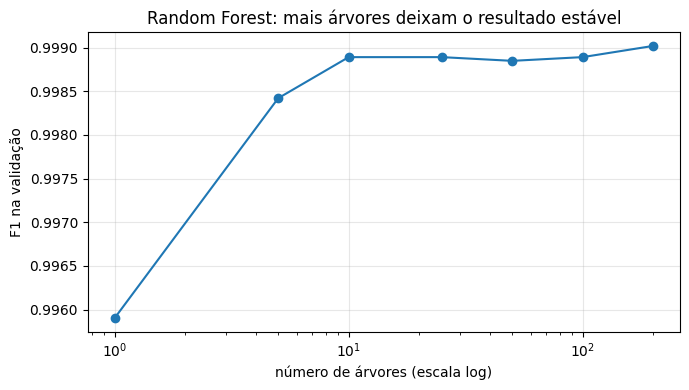

,árvores,F1 validação,erro OOB
0,1,0.9959,NaN
1,5,0.9984,NaN
2,10,0.9989,NaN
3,25,0.9989,0.0018
4,50,0.9988,0.0015
5,100,0.9989,0.0012
6,200,0.9990,0.0012


In [8]:
n_arvores = [1, 5, 10, 25, 50, 100, 200]
f1_rf, erro_oob = [], []

for n in n_arvores:
    usa_oob = n >= 25   # com poucas árvores o OOB não é confiável
    rf = RandomForestClassifier(n_estimators=n, oob_score=usa_oob, n_jobs=-1, random_state=SEED)
    rf.fit(X_tr, y_tr)
    f1_rf.append(f1_score(y_val, rf.predict(X_val)))
    erro_oob.append(1 - rf.oob_score_ if usa_oob else np.nan)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(n_arvores, f1_rf, "o-")
ax.set_xscale("log")
ax.set_xlabel("número de árvores (escala log)")
ax.set_ylabel("F1 na validação")
ax.set_title("Random Forest: mais árvores deixam o resultado estável")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figuras/rf_numero_arvores.png", dpi=150)
plt.show()

pd.DataFrame({"árvores": n_arvores, "F1 validação": f1_rf, "erro OOB": erro_oob}).round(4)

### XGBoost: taxa de aprendizado, rodadas e early stopping
No boosting, cada rodada adiciona uma árvore que tenta corrigir os erros das anteriores. A **taxa de aprendizado**
controla o quanto cada árvore nova conta. Com **early stopping**, o treino para quando a validação deixa de melhorar.

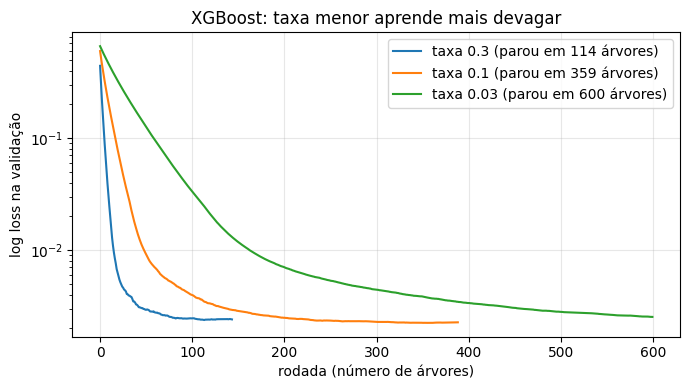

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))

for taxa in [0.3, 0.1, 0.03]:
    xgb = XGBClassifier(n_estimators=600, learning_rate=taxa, max_depth=6,
                        eval_metric="logloss", early_stopping_rounds=30,
                        random_state=SEED, n_jobs=-1)
    xgb.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
    curva = xgb.evals_result()["validation_0"]["logloss"]
    ax.plot(curva, label=f"taxa {taxa} (parou em {xgb.best_iteration + 1} árvores)")

ax.set_yscale("log")
ax.set_xlabel("rodada (número de árvores)")
ax.set_ylabel("log loss na validação")
ax.set_title("XGBoost: taxa menor aprende mais devagar")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figuras/xgb_taxa_aprendizado.png", dpi=150)
plt.show()

## 4. Ajuste dos hiperparâmetros (mesmo esforço para os três)
Para a comparação ser justa, cada modelo passa pela mesma busca:
- `RandomizedSearchCV` com **15 combinações** sorteadas
- validação cruzada estratificada de **3 dobras**, só no treino
- escolha pelo **F1**


In [10]:
N_ITER = 15
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

espacos = {
    "Árvore de Decisão": (
        DecisionTreeClassifier(random_state=SEED),
        {"max_depth": randint(3, 31),
         "min_samples_leaf": randint(1, 51),
         "criterion": ["gini", "entropy"],
         "ccp_alpha": loguniform(1e-6, 1e-2)}),   # ccp_alpha = poda
    "Random Forest": (
        RandomForestClassifier(random_state=SEED, n_jobs=-1),
        {"n_estimators": randint(50, 301),
         "max_depth": [None, 10, 20, 30],
         "min_samples_leaf": randint(1, 11),
         "max_features": ["sqrt", "log2", 0.3]}),
    "XGBoost": (
        XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric="logloss"),
        {"n_estimators": randint(100, 501),
         "learning_rate": loguniform(0.01, 0.3),
         "max_depth": randint(3, 11),
         "subsample": uniform(0.6, 0.4),
         "colsample_bytree": uniform(0.6, 0.4),
         "reg_lambda": loguniform(0.1, 10)}),      # reg_lambda = regularização
}

melhores = {}
for nome, (modelo, espaco) in espacos.items():
    busca = RandomizedSearchCV(modelo, espaco, n_iter=N_ITER, cv=cv, scoring="f1",
                               random_state=SEED, n_jobs=1, refit=False)
    inicio = time.perf_counter()
    busca.fit(X_train, y_train)
    duracao = time.perf_counter() - inicio
    melhores[nome] = busca.best_params_
    print(f"{nome}: F1 na validação cruzada = {busca.best_score_:.4f} (busca levou {duracao:.0f} s)")
    print("  melhores hiperparâmetros:", busca.best_params_)

Árvore de Decisão: F1 na validação cruzada = 0.9981 (busca levou 40 s)
  melhores hiperparâmetros: {'ccp_alpha': np.float64(3.7279259033769864e-06), 'criterion': 'gini', 'max_depth': 24, 'min_samples_leaf': 2}
Random Forest: F1 na validação cruzada = 0.9987 (busca levou 949 s)
  melhores hiperparâmetros: {'max_depth': 30, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 253}
XGBoost: F1 na validação cruzada = 0.9991 (busca levou 488 s)
  melhores hiperparâmetros: {'colsample_bytree': np.float64(0.608233797718321), 'learning_rate': np.float64(0.2708160864249968), 'max_depth': 6, 'n_estimators': 393, 'reg_lambda': np.float64(0.10035927878780913), 'subsample': np.float64(0.996884623716487)}


## 5. Avaliação no teste (uma vez só)
Agora sim usamos o KDDTest+. Cada modelo é treinado no treino inteiro com os melhores hiperparâmetros e medimos:
métricas, falsos negativos (ataques que passaram) e falsos positivos (alarmes falsos), tempo de treino e tempo de predição.

In [11]:
classes = {"Árvore de Decisão": DecisionTreeClassifier,
           "Random Forest": RandomForestClassifier,
           "XGBoost": XGBClassifier}
fixos = {"Árvore de Decisão": {"random_state": SEED},
         "Random Forest": {"random_state": SEED, "n_jobs": -1},
         "XGBoost": {"random_state": SEED, "n_jobs": -1, "eval_metric": "logloss"}}

finais = {}
previsoes = {}
matrizes = {}
linhas = []
um_fluxo = X_test.iloc[[0]]

for nome, Classe in classes.items():
    modelo = Classe(**melhores[nome], **fixos[nome])

    inicio = time.perf_counter()
    modelo.fit(X_train, y_train)
    tempo_treino = time.perf_counter() - inicio

    inicio = time.perf_counter()
    pred = modelo.predict(X_test)
    tempo_teste = time.perf_counter() - inicio

    # latência de um fluxo só (o caso de decidir em tempo quase real): mediana de 200 tentativas
    tempos = []
    for _ in range(200):
        inicio = time.perf_counter()
        modelo.predict(um_fluxo)
        tempos.append(time.perf_counter() - inicio)

    finais[nome] = modelo
    previsoes[nome] = pred
    matrizes[nome] = confusion_matrix(y_test, pred)
    vn, fp, fn, vp = matrizes[nome].ravel()

    linhas.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_test, pred),
        "Precisão": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "Ataques perdidos (FN)": fn,
        "Alarmes falsos (FP)": fp,
        "Treino (s)": tempo_treino,
        "Predição do teste todo (ms)": 1000 * tempo_teste,
        "Latência de 1 fluxo (ms)": 1000 * np.median(tempos),
    })

resultados = pd.DataFrame(linhas).set_index("Modelo")
resultados.to_csv("resultados/metricas.csv")
resultados.round(4)

,Acurácia,Precisão,Recall,F1,Ataques perdidos (FN),Alarmes falsos (FP),Treino (s),Predição do teste todo (ms),Latência de 1 fluxo (ms)
Modelo,,,,,,,,,
Árvore de Decisão,0.7929,0.9660,0.6594,0.7838,4371,298,1.7280,13.3266,1.5942
Random Forest,0.7703,0.9674,0.6173,0.7537,4911,267,27.0731,445.5702,77.6821
XGBoost,0.8017,0.9697,0.6727,0.7944,4200,270,15.4760,331.0573,14.7244


### Matrizes de confusão

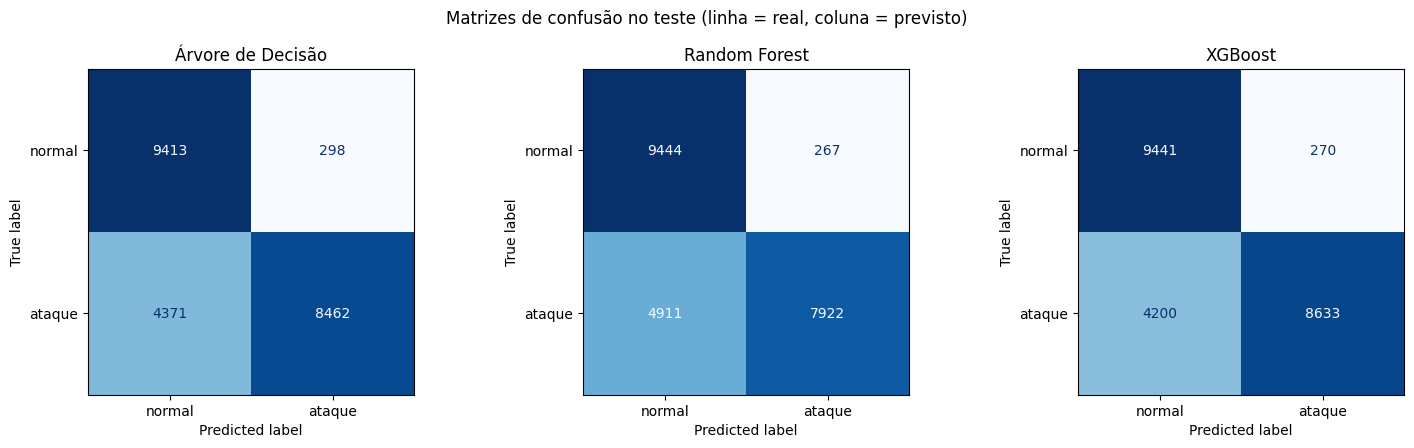

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (nome, matriz) in zip(axes, matrizes.items()):
    ConfusionMatrixDisplay(matriz, display_labels=["normal", "ataque"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(nome)
plt.suptitle("Matrizes de confusão no teste (linha = real, coluna = previsto)")
plt.tight_layout()
plt.savefig("figuras/matrizes_confusao.png", dpi=150)
plt.show()

### Precisão, recall e F1 lado a lado

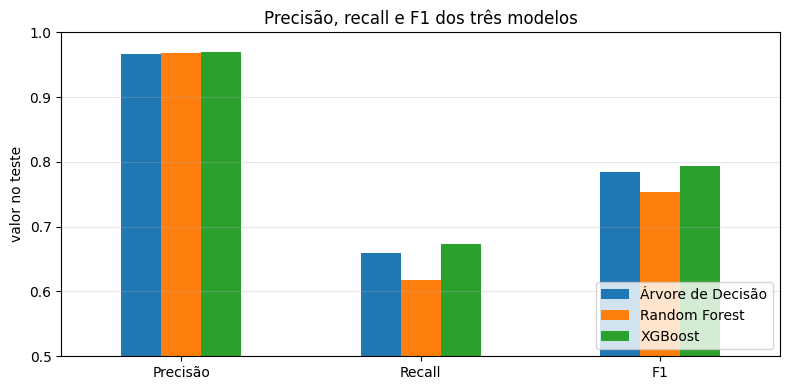

In [13]:
ax = resultados[["Precisão", "Recall", "F1"]].T.plot.bar(figsize=(8, 4), rot=0)
ax.set_ylim(0.5, 1.0)
ax.set_ylabel("valor no teste")
ax.set_title("Precisão, recall e F1 dos três modelos")
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("figuras/metricas.png", dpi=150)
plt.show()

### Curva ROC (só para diagnóstico)
A curva ROC mostra o que aconteceria com outros limiares de decisão (o padrão é 0,5).
Usamos ela **só para olhar**: não escolhemos limiar nenhum com o teste, porque isso seria vazamento de dados.

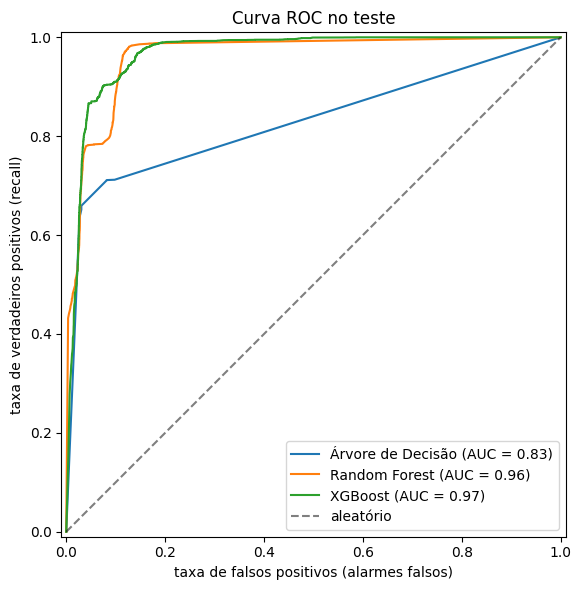

In [14]:
fig, ax = plt.subplots(figsize=(6, 6))
for nome, modelo in finais.items():
    RocCurveDisplay.from_estimator(modelo, X_test, y_test, name=nome, ax=ax)
ax.plot([0, 1], [0, 1], "k--", alpha=0.5, label="aleatório")
ax.set_xlabel("taxa de falsos positivos (alarmes falsos)")
ax.set_ylabel("taxa de verdadeiros positivos (recall)")
ax.set_title("Curva ROC no teste")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("figuras/curva_roc.png", dpi=150)
plt.show()

### Onde os modelos erram: recall por categoria de ataque
Aqui separamos os ataques do teste por categoria (DoS, Probe, R2L, U2R) e também em conhecidos (o tipo existe no treino)
e novos (o tipo só existe no teste). O recall de cada grupo é a fração dos ataques daquele grupo que o modelo pegou.

In [15]:
eh_novo = teste_df["label"].isin(tipos_novos).values
categoria_teste = teste_df["categoria"].values

recall_categoria = {}
for nome, pred in previsoes.items():
    linha = {}
    for cat in ["DoS", "Probe", "R2L", "U2R"]:
        linha[cat] = pred[categoria_teste == cat].mean()
    linha["Ataques conhecidos"] = pred[(y_test == 1) & ~eh_novo].mean()
    linha["Ataques novos"] = pred[(y_test == 1) & eh_novo].mean()
    recall_categoria[nome] = linha

recall_categoria = pd.DataFrame(recall_categoria).T
recall_categoria.loc["nº de ataques no teste"] = (
    [(categoria_teste == c).sum() for c in ["DoS", "Probe", "R2L", "U2R"]]
    + [((y_test == 1) & ~eh_novo).sum(), ((y_test == 1) & eh_novo).sum()])
recall_categoria.to_csv("resultados/recall_por_categoria.csv")
recall_categoria.round(3)

,DoS,Probe,R2L,U2R,Ataques conhecidos,Ataques novos
Árvore de Decisão,0.833,0.809,0.093,0.180,0.774,0.383
Random Forest,0.801,0.732,0.057,0.105,0.769,0.249
XGBoost,0.870,0.806,0.066,0.075,0.773,0.430
nº de ataques no teste,7458.000,2421.000,2754.000,200.000,9083.000,3750.000


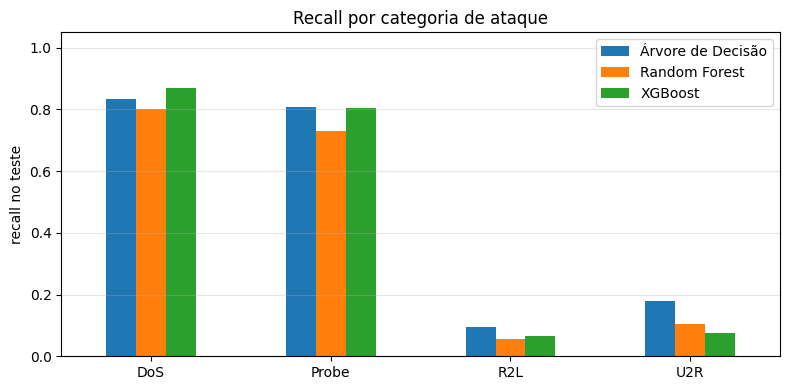

In [16]:
ax = recall_categoria.drop("nº de ataques no teste")[["DoS", "Probe", "R2L", "U2R"]].T.plot.bar(figsize=(8, 4), rot=0)
ax.set_ylim(0, 1.05)
ax.set_ylabel("recall no teste")
ax.set_title("Recall por categoria de ataque")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("figuras/recall_por_categoria.png", dpi=150)
plt.show()

## 6. Interpretabilidade
- A **árvore** pode ser impressa e auditada regra por regra.
- A **Random Forest** e o **XGBoost** têm centenas de árvores, então usamos a importância dos atributos como resumo.

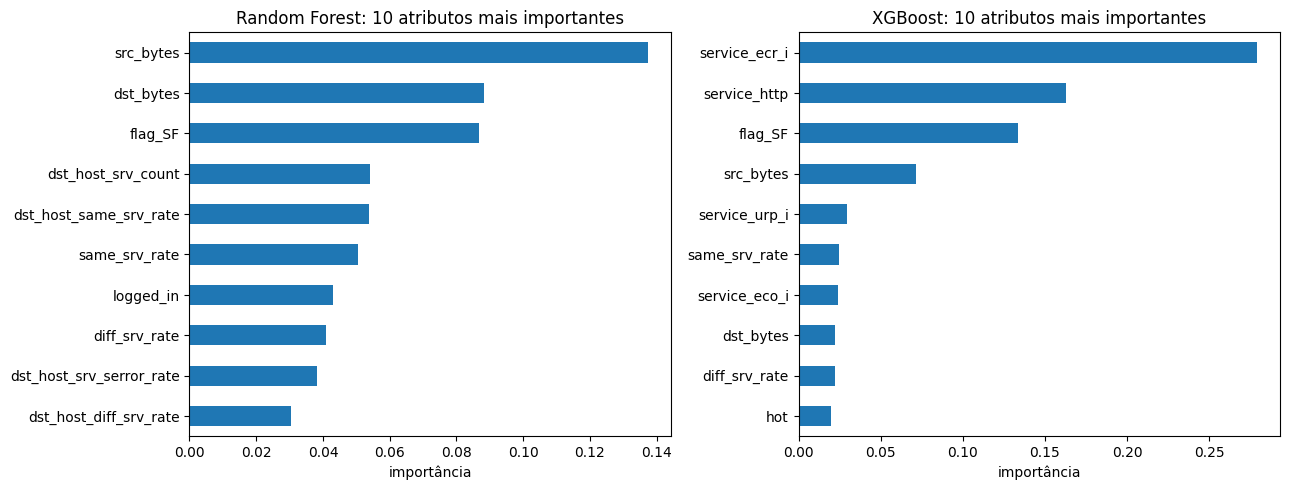

Árvore final: profundidade 20 e 205 folhas
Random Forest final: 253 árvores
XGBoost final: 393 árvores


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, nome in zip(axes, ["Random Forest", "XGBoost"]):
    importancia = pd.Series(finais[nome].feature_importances_, index=X_train.columns).nlargest(10)
    importancia[::-1].plot.barh(ax=ax)
    ax.set_title(f"{nome}: 10 atributos mais importantes")
    ax.set_xlabel("importância")
plt.tight_layout()
plt.savefig("figuras/importancia_atributos.png", dpi=150)
plt.show()

arvore_final = finais["Árvore de Decisão"]
print(f"Árvore final: profundidade {arvore_final.get_depth()} e {arvore_final.get_n_leaves()} folhas")
print(f"Random Forest final: {len(finais['Random Forest'].estimators_)} árvores")
print(f"XGBoost final: {finais['XGBoost'].get_booster().num_boosted_rounds()} árvores")

## 7. Para a conclusão
Perguntas que usamos para escrever a recomendação no artigo:
- Qual modelo deixou passar menos ataques (maior recall)? Quantos alarmes falsos isso custou?
- A diferença de F1 entre a floresta e o boosting é grande ou pequena?
- Os três são rápidos o bastante para decidir um fluxo em tempo quase real?
- Os ataques novos e as categorias R2L e U2R derrubam os três modelos? O que isso diz sobre usar só aprendizado supervisionado?